<a href="https://colab.research.google.com/github/soyeonkm/datasci101/blob/main/module2_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module Project 2: American Households

The US Census Bureau needs to know how the country’s 120 million
households live: who owns and who rents, how many cars sit in the
driveway, what a household earns, and many other things. The **American
Community Survey (ACS)** asks about 3.5 million people a year and uses
those responses to **infer** results for the entire US population.
Selections of these responses are published as Public Use Microdata or
PUMS, with certain information withheld or modified for reasons of
privacy.

Suppose your city wants the same picture of its own residents and has
asked you to design the survey. It can afford to ask about **1,000
households**. Before spending the money, you practice on a table where
the truth is known: a large ACS extract that this project treats as if
it were your city.

Part 1 gets that table loaded and cleaned. Part 2 describes the
households in it through their distributions, typical values and spread.
Part 3 turns proportions into probabilities and draws the first samples.
Part 4 treats the mean of a sample as a random variable and asks how it
behaves. Part 5 uses the Gaussian distribution to say how far one sample
can land from the truth, and how many households your survey needs.
**Each part uses one plenary session, in order**, so you can develop
your project over the course of the module.

Each part ends with a **Your survey** prompt. Your city’s survey will
ask about more than income and tenure, so in the first prompt you choose
one more trait of a household to measure, a column the numbered
questions do not use. The later prompts repeat each part’s main
computation on your column, or let you choose again. The quiz will ask
what you chose and what you found, so the results need to be on the
page.

**Display every result a question asks for.** You will work later from a
printed copy of this notebook, so a result that is not displayed will
not be on the page. Put the value on the last line of the cell so it
prints. When a question asks for several values and gives you one cell,
put them in a dictionary and make that the last line, as in
`{"rows": acs.shape[0], "columns": acs.shape[1]}`, so every value prints
with a label.

Most questions are followed by a **check cell** of commented-out
`assert` lines you can use to test your work; the cell itself tells you
how. A check that passes says your result has the right approach and
produces the right value. A check that fails names the line that failed.

For each prompt below you will be asked a motivating question. Do not
answer the question right away. Go through the steps given to help you
get the information you need to answer the question. On the quiz you
will be asked what you found and how you will answer the motivating
questions.

### The data

The data set is the 2018 **Public Use Microdata Sample (PUMS)** of the
ACS, cut down to a random subset of housing units and a handful of
columns. Each **row is one housing unit**, whether or not anyone lives
in it. A unit may be a house, an apartment or a mobile home. The Census
Bureau’s **PUMS data dictionary** tells you what each column measures
and what its codes mean:

<https://www2.census.gov/programs-surveys/acs/tech_docs/pums/data_dict/PUMS_Data_Dictionary_2018.pdf>

Keep it open. The dictionary has a section for housing records and one
for person records. Every column in this table is a housing record
variable, listed under its name in capitals.

Four columns carry the numbered questions. `NP` counts the people living
in the unit. `TEN` records how the unit is held, as a code from 1 to 4.
`VEH` counts the vehicles available, and 6 stands for six or more.
`HINCP` is the household’s income over the past twelve months, in
dollars, and a negative value is a loss.

# Part 1: The table (Plenary 2.1)

In [1]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt

The data live at this address. Loading from the URL means you never need
to manage a file.

In [2]:
acs_url = "https://github.com/UM-Data-Science-101/data/raw/refs/heads/main/Old/pums_short.csv.gz"

## Question 1: Loading

> **Motivation.** How many housing units did the Census Bureau’s extract
> include, and what was recorded about each one?

Read the data into a table called **`acs`**. Then display how many rows
and columns it has, and the names of its columns.

*Hint: the plenary 2.1 session loads its tables from a URL the same
way.*

In [3]:
acs = pd.read_csv(acs_url)


In [4]:
{
    "rows": acs.shape[0],
    "columns": acs.shape[1],
    "column_names": acs.columns.tolist()
}

{'rows': 276632,
 'columns': 31,
 'column_names': ['DIVISION',
  'PUMA',
  'REGION',
  'ST',
  'NP',
  'MRGP',
  'RNTP',
  'TEN',
  'VALP',
  'VEH',
  'YBL',
  'FES',
  'FINCP',
  'FPARC',
  'HHT',
  'HINCP',
  'HUPAC',
  'MV',
  'NOC',
  'NPF',
  'NR',
  'NRC',
  'PARTNER',
  'R18',
  'R60',
  'R65',
  'TAXAMT',
  'WIF',
  'WKEXREL',
  'WORKSTAT',
  'FFINCP']}

In [8]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert type(acs) == pd.DataFrame
assert acs.shape == (276632, 31)
assert "HINCP" in acs.columns
assert "TEN" in acs.columns

## Question 2: Labels for codes

> **Motivation.** Every later table and plot of tenure will show bare
> codes unless we give them names. Can the table carry the meaning of
> each code along with it?

The codes in `TEN` are labels, not amounts. Give them names so that
later output is readable.

The `replace` method takes a **dictionary** of old value to new value
and returns a copy of the Series with the swaps made. Here it is on a
small Series.

In [ ]:
sizes = pd.Series([1, 3, 2, 1])
sizes.replace({1: "small", 2: "medium", 3: "large"})

,0
0,small
1,large
2,medium
3,small


Use it to add a column **`TEN_name`** to `acs` holding these names for
the four codes:

| code | `TEN_name`               |
|------|--------------------------|
| 1    | `"Owned with mortgage"`  |
| 2    | `"Owned free and clear"` |
| 3    | `"Rented"`               |
| 4    | `"No rent paid"`         |

Then display the **unique** values of the new column, with the `unique`
method.

*Hint: the plenary 2.1 session ends with an exercise on unique values.*

In [9]:
# your code here
acs["TEN_name"] = acs["TEN"].replace({
    1: "Owned with mortgage",
    2: "Owned free and clear",
    3: "Rented",
    4: "No rent paid"
})

acs["TEN_name"].unique()

array(['Owned with mortgage', 'Owned free and clear', 'Rented', nan,
       'No rent paid'], dtype=object)

In [10]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert "TEN_name" in acs.columns
assert (acs["TEN_name"] == "Rented").sum() == 69741
assert (acs["TEN_name"] == "Owned with mortgage").sum() == 103923
assert acs["TEN_name"].isna().sum() == acs["TEN"].isna().sum()

The `nan` in the output is worth noticing: `replace` left the missing
values missing. A vacant unit still has no tenure, whatever we call the
codes.

## Question 3: New columns

> **Motivation.** A household of six living on 100,000 dollars is not in
> the same position as a household of one. What does income look like
> per person, and how many households count as high income?

### (a) Income per person

Add a column **`PER_PERSON`** holding income per household member:
`HINCP` divided by `NP`. Display the largest value.

### (b) High income

Add a column **`HIGH_INCOME`** that is `True` when `HINCP` is more than
100,000 and `False` otherwise. Display how many rows are `True`, with
`sum`, and the proportion of rows that are `True`, which is that count
divided by the number of rows in `acs`. Display all three values from
(a) and (b) in one dictionary.

`HIGH_INCOME` comes back in Part 3.

*Hint: the plenary 2.1 video’s slide “Working with more than one column
at a time” divides one column by another, and the session’s “Filtering
Rows” exercise counts the `True` values in a comparison.*

In [13]:
# your code here
# a)
acs["PER_PERSON"] = acs["HINCP"] / acs["NP"]

# b)
acs["HIGH_INCOME"] = acs["HINCP"] > 100000

{
    "max_per_person": acs["PER_PERSON"].max(),
    "high_income_count": acs["HIGH_INCOME"].sum(),
    "high_income_proportion": acs["HIGH_INCOME"].sum() / acs.shape[0]
}

{'max_per_person': 1290000.0,
 'high_income_count': np.int64(73223),
 'high_income_proportion': np.float64(0.2646946123369675)}

In [14]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert acs["PER_PERSON"].max() == acs["HINCP"].max() / 2
assert acs["HIGH_INCOME"].dtype == bool
assert acs["HIGH_INCOME"].sum() == 73223

## Question 4: Rows

> **Motivation.** Some rows are not households at all. How many housing
> units are vacant, and how do we keep only the occupied ones?

### (a) Missing values

Vacant units have no household in them, so they have no income and no
tenure to report. The PUMS dictionary lists this as code `b`, “N/A
(GQ/vacant)”, for both `HINCP` and `TEN`; pandas shows it as `NaN`, and
`isna` finds it. Display, in one dictionary, the number of rows in `acs`
missing `HINCP`, that number divided by the number of rows, the number
of rows missing `TEN`, and the number of rows missing **both**, which is
the count of `True` values in the two `isna` results joined by `&`.

*Hint: the plenary 2.1 session’s slide on missing data uses `isna`, and
its “Filtering Rows” exercise joins two conditions with `&`.*

In [15]:
# your code here
{
    "missing_HINCP": acs["HINCP"].isna().sum(),
    "missing_HINCP_proportion": acs["HINCP"].isna().sum() / acs.shape[0],
    "missing_TEN": acs["TEN"].isna().sum(),
    "missing_both": (acs["HINCP"].isna() & acs["TEN"].isna()).sum()
}

{'missing_HINCP': np.int64(25613),
 'missing_HINCP_proportion': np.float64(0.0925887099106394),
 'missing_TEN': np.int64(25613),
 'missing_both': np.int64(25613)}

### (b) Occupied units only

Make a table **`households`** holding only the rows where `HINCP` is not
missing. The `dropna` method drops rows with missing values. On its own
it drops every row that is missing *any* column, which here would be
nearly all of them, so name the one column that matters in a list passed
as `subset`. Here it is on a small table.

In [ ]:
small = pd.DataFrame({"a": [1, None, 3], "b": [None, 5, 6]})
small.dropna(subset=["a"])

,a,b
0,1.0,NaN
2,3.0,6.0


Display the shape of the new table and the smallest value of `NP` in it,
in one dictionary.

The rest of the project uses `households`, not `acs`.

In [16]:
# your code here

households = acs.dropna(subset=["HINCP"])

{
    "shape": households.shape,
    "min_NP": households["NP"].min()
}

{'shape': (251019, 34), 'min_NP': 1}

In [17]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert households.shape[0] == 251019
assert "PER_PERSON" in households.columns
assert households["HINCP"].isna().sum() == 0
assert households.shape[0] == acs["HINCP"].count()
assert households["NP"].min() == 1
assert households["TEN_name"].isna().sum() == 0

## Your survey: a column of your own

> **Motivation.** Your city’s survey will ask about more than income and
> tenure. What else about a household is worth measuring, and for which
> households does the answer even exist?

Choose one of the columns `NOC`, `NRC`, `NPF`, `FINCP`, `RNTP`, `MRGP`,
`VALP` or `TAXAMT`, and look it up in the data dictionary. Each records
an amount rather than a code. Every later **Your survey** prompt uses
the column you choose here.

Store the column’s name as a string in **`my_col`**, so that
`households[my_col]` picks it out the way `households["HINCP"]` does.
Six of these columns have no value for many households. Keep the values
that exist as **`my_values`**, using `households[my_col].dropna()`,
which drops the missing entries of a single column. Display one
dictionary holding the column’s name, the number of households
`my_values` covers, the number of rows in `households`, and the number
of distinct values, the smallest value and the largest value in
`my_values`.

*Hint: Question 4 used `dropna` on the whole table with `subset`. On one
column it needs no argument.*

In [18]:
# your code here

my_col = "NOC"

my_values = households[my_col].dropna()

{
    "column": my_col,
    "households_covered": my_values.shape[0],
    "total_households": households.shape[0],
    "distinct_values": my_values.nunique(),
    "minimum": my_values.min(),
    "maximum": my_values.max()
}

{'column': 'NOC',
 'households_covered': 251019,
 'total_households': 251019,
 'distinct_values': 13,
 'minimum': 0.0,
 'maximum': 12.0}

In [19]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert my_col in ["NOC", "NRC", "NPF", "FINCP", "RNTP", "MRGP", "VALP", "TAXAMT"]
assert my_values.isna().sum() == 0
assert len(my_values) == households[my_col].count()
assert len(my_values) > 1000

# Part 2: Distributions (Plenary 2.2)

Imagine `households` is a population and picture drawing one row from it
at random. Any column then becomes a **random variable**, and its
`value_counts(normalize=True)` is that variable’s **distribution**.

## Question 5: Categorical distributions

> **Motivation.** What share of households own their home, and what
> share rent? How many vehicles does a typical household keep?

### (a) Tenure

Compute and display the distribution of `TEN_name`, sorted by index, as
**`ten_dist`**.

*Hint: the plenary 2.2 slide “Computing distributions” does this for one
column of the Spotify data.*

In [20]:
# your code here

ten_dist = households["TEN_name"].value_counts(normalize=True).sort_index()

ten_dist

,proportion
TEN_name,
No rent paid,0.018620
Owned free and clear,0.289544
Owned with mortgage,0.414005
Rented,0.277832


In [21]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert abs(ten_dist.sum() - 1) < 0.000001
assert abs(ten_dist["Rented"] - 0.27783) < 0.0001
assert ten_dist.min() > 0

### (b) Vehicles

`VEH` is ordinal: 0 means no vehicle, 1 means one, up to 6 for “6 or
more”. Compute its distribution, sorted by index, as **`veh_dist`**. Its
**cumulative** version, from `cumsum`, keeps a running total down the
sorted Series, so each entry is the proportion of households with that
many vehicles or fewer. In the first cell, display `veh_dist` and its
cumulative version in one dictionary. The labels print as `2.0` rather
than `2` because `acs["VEH"]` had missing values, so pandas stored the
whole column as decimals.

In the second cell, display three numbers in one dictionary. Pull the
proportion of households with **two or fewer** vehicles out of the
cumulative distribution with square brackets, as `veh_dist.cumsum()[2]`.
Compute the same proportion a second way, as the `mean` of
`households["VEH"] <= 2`. Then find the **mode** of `VEH` with `idxmax`
on `veh_dist`.

*Hint: the plenary 2.2 slide “Computing the mode” reads a mode off
`value_counts`, and `idxmax`, from the plenary 2.1 video’s slide
“min/max and argmin/argmax methods”, returns the label of the largest
entry.*

In [22]:
# your code here
veh_dist = households["VEH"].value_counts(normalize=True).sort_index()

{
    "veh_dist": veh_dist,
    "cumulative": veh_dist.cumsum()
}

{'veh_dist': VEH
 0.0    0.072987
 1.0    0.313223
 2.0    0.380214
 3.0    0.156630
 4.0    0.053490
 5.0    0.015883
 6.0    0.007573
 Name: proportion, dtype: float64,
 'cumulative': VEH
 0.0    0.072987
 1.0    0.386210
 2.0    0.766424
 3.0    0.923054
 4.0    0.976544
 5.0    0.992427
 6.0    1.000000
 Name: proportion, dtype: float64}

In [23]:
# your code here
{
    "two_or_fewer_cumsum": veh_dist.cumsum()[2],
    "two_or_fewer_mean": (households["VEH"] <= 2).mean(),
    "mode": veh_dist.idxmax()
}

{'two_or_fewer_cumsum': np.float64(0.7664240555495798),
 'two_or_fewer_mean': np.float64(0.7664240555495799),
 'mode': np.float64(2.0)}

In [24]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert abs(veh_dist.sum() - 1) < 0.000001
assert abs(veh_dist.cumsum()[2] - (households["VEH"] <= 2).mean()) < 0.000001
assert abs(veh_dist.cumsum()[2] - 0.76642) < 0.0001
assert veh_dist.cumsum()[6] > 0.999999
assert veh_dist.idxmax() == 2

## Question 6: A numeric distribution

> **Motivation.** What does a typical American household earn, and how
> spread out are incomes?

Household income has thousands of distinct values, so `value_counts` is
no use.

### (a) Two plots of income

Draw a **histogram** of `HINCP` in `households` with `bins=100`, which
sets the number of bars, and a **boxplot** of the same column with
`showfliers=False`, which hides the points beyond the whiskers.

*Hint: the plenary 2.2 slides “Box plots” and “Histograms” draw both
plots for song durations.*

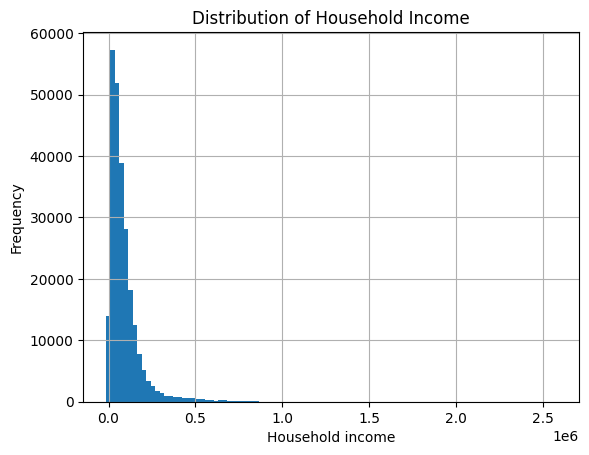

In [25]:
# your code here
households["HINCP"].hist(bins=100)
plt.xlabel("Household income")
plt.ylabel("Frequency")
plt.title("Distribution of Household Income")
plt.show()

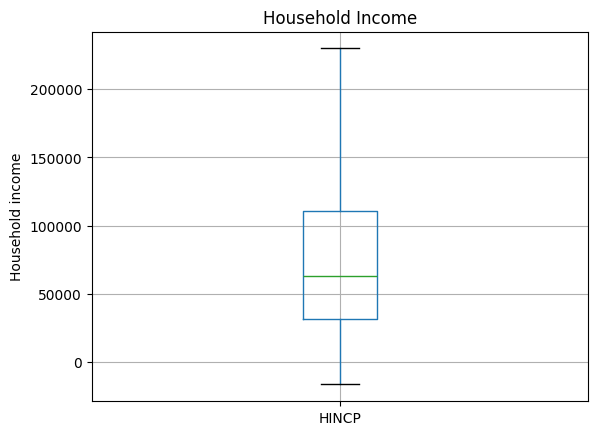

In [26]:
# your code here
households.boxplot(column="HINCP", showfliers=False)
plt.ylabel("Household income")
plt.title("Household Income")
plt.show()

### (b) Robust summaries

Two measures of spread are less sensitive to a long tail than the
standard deviation. Write them as two functions, then a third that uses
both. The next question uses all three on two groups.

**`iqr(values)`** takes a Series of numbers and returns the
**interquartile range**, the 0.75 quantile minus the 0.25 quantile. The
`quantile` method takes the probability as its argument.

**`mad(values)`** takes a Series of numbers and returns the **median
absolute deviation**, the median of the absolute distances from the
median. This is one chained expression.

**`summarize(values)`** takes a Series of numbers and returns a
**dictionary** with the keys `"mean"`, `"median"`, `"std"`, `"iqr"` and
`"mad"`, in that order, holding the five summaries. Call your own `iqr`
and `mad` for the last two.

A function can return a dictionary, as this one does.

In [ ]:
def smallest_and_largest(values):
    return {"smallest": values.min(), "largest": values.max()}

smallest_and_largest(pd.Series([3, 1, 2]))

{'smallest': 1, 'largest': 3}

Define all three functions in the first cell and end it with `iqr` and
`mad` demonstrated on `pd.Series([1, 2, 3, 4, 5, 6, 7, 8])`, in one
dictionary. In the second cell display `summarize(households["HINCP"])`.

*Hint: the plenary 2.2 session’s slides “The Interquartile Range” and
“Median Absolute Deviation” compute both, the second as one chained
expression.*

In [28]:
# your code here
def iqr(values):
    return values.quantile(0.75) - values.quantile(0.25)

def mad(values):
    return (values - values.median()).abs().median()

def summarize(values):
    return {
        "mean": values.mean(),
        "median": values.median(),
        "std": values.std(),
        "iqr": iqr(values),
        "mad": mad(values)
    }

test_values = pd.Series([1, 2, 3, 4, 5, 6, 7, 8])

{
    "iqr": iqr(test_values),
    "mad": mad(test_values)
}

{'iqr': np.float64(3.5), 'mad': 2.0}

In [29]:
# your code here

summarize(households["HINCP"])

{'mean': np.float64(89650.28667949438),
 'median': 63000.0,
 'std': 100094.58348162091,
 'iqr': np.float64(79200.0),
 'mad': 37000.0}

In [30]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert iqr(pd.Series([1, 2, 3, 4, 5, 6, 7, 8])) == 3.5
assert iqr(pd.Series([5, 5, 5, 5])) == 0
assert mad(pd.Series([1, 2, 3, 4, 5])) == 1
assert mad(pd.Series([1, 1, 1, 100])) == 0

three = summarize(pd.Series([1, 2, 3]))
assert list(three.keys()) == ["mean", "median", "std", "iqr", "mad"]
assert three["mean"] == 2
assert three["median"] == 2
assert three["std"] == 1.0
assert three["iqr"] == 1.0
assert three["mad"] == 1

assert summarize(households["HINCP"])["median"] == 63000
assert abs(summarize(households["HINCP"])["iqr"] - 79200) < 1

## Question 7: Comparing groups

> **Motivation.** Do owners and renters have different incomes?

### (a) Owners and renters

Make two tables from `households`: **`owners`** holding the rows whose
`TEN` is 1 **or** 2, and **`renters`** holding the rows whose `TEN` is
3. Join the two conditions with `|`, which means “or”. It works like the
`&` in the plenary 2.1 session’s “Filtering Rows” exercise, with
parentheses around each condition. Display the number of rows in each
table in one dictionary.

In [32]:
# your code here
owners = households[(households["TEN"] == 1) | (households["TEN"] == 2)]
renters = households[households["TEN"] == 3]

{
    "owners": owners.shape[0],
    "renters": renters.shape[0]
}

{'owners': 176604, 'renters': 69741}

In [33]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert owners.shape[0] == 176604
assert renters.shape[0] == 69741
assert owners.shape[0] + renters.shape[0] < households.shape[0]
assert (renters["TEN_name"] == "Rented").all()

### (b) A boxplot by group

Draw one boxplot with `TEN_name` on the x axis and `HINCP` on the y
axis, with `showfliers=False`.

*Hint: the plenary 2.2 session’s slide “Box plots by group” draws one.*

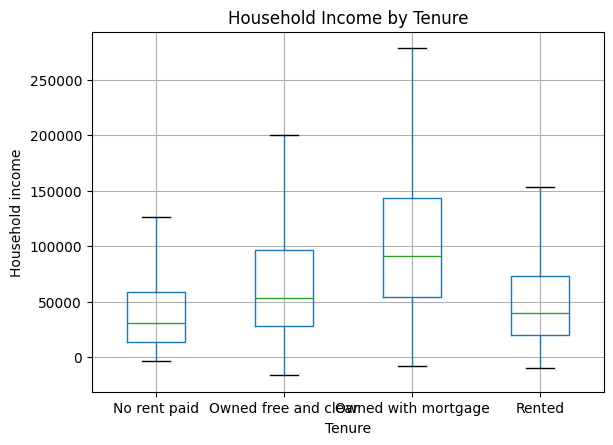

In [35]:
# your code here
households.boxplot(
    column="HINCP",
    by="TEN_name",
    showfliers=False
)

plt.xlabel("Tenure")
plt.ylabel("Household income")
plt.title("Household Income by Tenure")
plt.suptitle("")
plt.show()

### (c) Summaries side by side

Build a table with one column for owners and one for renters, each
holding the five summaries: `pd.DataFrame` accepts a dictionary whose
values are the two dictionaries `summarize` returns, under the keys
`"owners"` and `"renters"`. Call it **`compare`** and display it. Then
display the difference in **medians** (owners minus renters) and the
ratio of **IQRs** (owners over renters) in one dictionary.

*Hint: the plenary 2.2 session’s slide “Summaries in a Table” builds a
table from two dictionaries.*

In [36]:
# your code here
compare = pd.DataFrame({
    "owners": summarize(owners["HINCP"]),
    "renters": summarize(renters["HINCP"])
})

compare

,owners,renters
mean,103480.937385,57598.685594
median,75000.000000,40000.000000
std,108486.855264,66363.128974
iqr,86900.000000,53500.000000
mad,40000.000000,24400.000000


In [37]:
# your code here
{
    "median_difference": compare.loc["median", "owners"] - compare.loc["median", "renters"],
    "iqr_ratio": compare.loc["iqr", "owners"] / compare.loc["iqr", "renters"]
}

{'median_difference': np.float64(35000.0),
 'iqr_ratio': np.float64(1.6242990654205607)}

In [38]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert list(compare.columns) == ["owners", "renters"]
assert list(compare.index) == ["mean", "median", "std", "iqr", "mad"]
assert compare.loc["median", "owners"] > compare.loc["median", "renters"]
assert compare.loc["median", "owners"] == owners["HINCP"].median()

## Your survey: the distribution of your column

> **Motivation.** What is a typical value of your column in your city,
> and how much do households differ on it?

Draw a histogram of your column from `households`, passing `my_col` as
`x`. Then store `summarize(my_values)` as **`my_summary`** and display
it.

*Hint: Question 6 drew a histogram of `HINCP` the same way.*

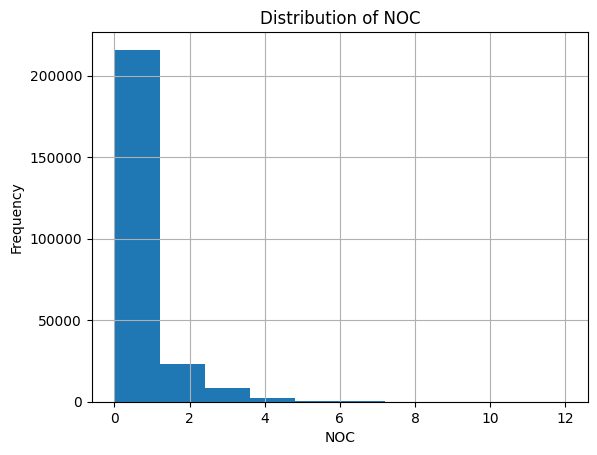

In [39]:
# your code here
households.hist(column=my_col)
plt.xlabel(my_col)
plt.ylabel("Frequency")
plt.title(f"Distribution of {my_col}")
plt.show()

In [40]:
# your code here
my_summary = summarize(my_values)

my_summary

{'mean': np.float64(0.45102163581242855),
 'median': 0.0,
 'std': 0.9325647522768497,
 'iqr': np.float64(0.0),
 'mad': 0.0}

In [41]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert list(my_summary.keys()) == ["mean", "median", "std", "iqr", "mad"]
assert my_summary["median"] == my_values.median()
assert my_summary["iqr"] >= 0 and my_summary["mad"] >= 0

# Part 3: Probability and sampling (Plenary 2.3)

A population can be treated as a random variable: drawing one household
uniformly at random makes every proportion in `households` a
probability.

The ACS is itself a sample: the Census Bureau does not survey every
household, and neither will your city. From here on `households` plays
the role of your city’s whole population of occupied housing units, so
that the truth is known and every sample can be checked against it.

## Question 8: Probability from a population

> **Motivation.** If you knock on the door of a randomly chosen renter,
> how likely is it that the household earns more than 100,000 dollars?
> Is that chance any different from the chance for a household picked at
> random from everyone?

Consider two events for a household drawn uniformly at random from
`households`. $A$ is the event that the household **rents** (`TEN` is
3), and $B$ is the event that its income is **above 100,000**.

### (a) Two events

Make a boolean Series **`is_renter`** for $A$. For $B$ you already have
one: the `HIGH_INCOME` column from Question 3 came along into
`households`. Store it under the name **`is_high`** so the two names
match. Display $P(A)$, $P(B)$ and $P(A \text{ and } B)$, taking means of
boolean Series, with `&` for “and”, in one dictionary.

*Hint: the “Filtering Rows” exercise in the plenary 2.1 session uses
`&`.*

In [42]:
# your code here

is_renter = households["TEN"] == 3
is_high = households["HIGH_INCOME"]

{
    "P(A)": is_renter.mean(),
    "P(B)": is_high.mean(),
    "P(A and B)": (is_renter & is_high).mean()
}

{'P(A)': np.float64(0.27783155856727976),
 'P(B)': np.float64(0.29170301849660785),
 'P(A and B)': np.float64(0.038873551404475355)}

In [43]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert is_renter.dtype == bool and is_high.dtype == bool
assert abs(is_renter.mean() - ten_dist["Rented"]) < 0.000001
assert (is_renter & is_high).mean() <= is_renter.mean()
assert (is_renter & is_high).mean() <= is_high.mean()
assert abs(is_high.mean() - 0.29170) < 0.0001

### (b) Conditional probability

Compute $P(B \mid A)$, the probability of a high income **given** that
the household rents, in two ways, first as $P(A \text{ and } B) / P(A)$
and then directly as the mean of `is_high` restricted to the renters,
which is `is_high[is_renter].mean()`, and display both. Then display
$P(B \mid
\text{not } A)$, the same probability among households that do not rent,
using `is_high[is_renter == False].mean()`. Display all three in one
dictionary.

*Hint: the plenary 2.3 session computes a conditional probability as a
restricted mean and checks independence two ways.*

In [44]:
# your code here
{
    "P(B|A)_formula": (is_renter & is_high).mean() / is_renter.mean(),
    "P(B|A)_direct": is_high[is_renter].mean(),
    "P(B|not A)": is_high[is_renter == False].mean()
}

{'P(B|A)_formula': np.float64(0.13991769547325103),
 'P(B|A)_direct': np.float64(0.13991769547325103),
 'P(B|not A)': np.float64(0.35009764008870353)}

In [45]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert abs((is_renter & is_high).mean() / is_renter.mean() - is_high[is_renter].mean()) < 0.000001
assert is_high[is_renter].mean() < is_high[is_renter == False].mean()

### (c) Independence

Display $P(A) \, P(B)$ beside $P(A \text{ and } B)$ from part (a), in
one dictionary.

*Hint: the plenary 2.3 session’s “Independence” section makes this
comparison.*

In [46]:
# your code here
{
    "P(A)P(B)": is_renter.mean() * is_high.mean(),
    "P(A and B)": (is_renter & is_high).mean()
}

{'P(A)P(B)': np.float64(0.08104430426769259),
 'P(A and B)': np.float64(0.038873551404475355)}

## Question 9: The population

> **Motivation.** Your survey will estimate the mean income of all
> households from 1,000 of them. To judge how well it does, we need the
> truth it is aiming at. What is the mean income of all households, how
> much do incomes vary, and is 1,000 a small enough slice of the
> population to sample freely?

A survey of 1,000 households estimates the **mean income** of all of
them. In `households` the truth is available. Compute three population
quantities. **`mu`** is the population mean of `HINCP` in `households`.
**`sigma`** is its population standard deviation, from `std`; the
$N - 1$ in that method’s denominator makes no difference at this size.
**`N`** is the number of households. Display the three, and
$(N - n) / N$ for $n = 1000$, in one dictionary.

*Hint: plenary 2.3’s slide “Simple Random Samples” states the rule, and
the 2.3 session computes the ratio for two sample sizes.*

In [47]:
# your code here
mu = households["HINCP"].mean()
sigma = households["HINCP"].std()
N = households.shape[0]

{
    "mu": mu,
    "sigma": sigma,
    "N": N,
    "(N - 1000) / N": (N - 1000) / N
}

{'mu': np.float64(89650.28667949438),
 'sigma': 100094.58348162091,
 'N': 251019,
 '(N - 1000) / N': 0.9960162378146674}

In [48]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert abs(mu - 89650.29) < 0.01
assert abs(sigma - 100094.58) < 0.01
assert N == 251019
assert (N - 1000) / N > 0.99

## Question 10: Sampling functions

> **Motivation.** One survey is one sample. If the survey could be run
> again and again, what would the run of results look like?

Write two functions.

**`sample_mean(n)`** takes a sample size and returns the mean of **one**
simple random sample of `n` values from `households["HINCP"]`. The
`sample` method draws rows from a table, as in plenary 2.3, and works on
a single column the same way.

**`simulate_means(n, reps)`** takes a sample size and a number of
samples, and returns a **Series** of `reps` sample means, each from a
fresh sample of size `n`. Build the list with a comprehension that calls
`sample_mean`, then wrap it in `pd.Series`.

Demonstrate `sample_mean(10)` and `simulate_means(10, 5)` in one
dictionary.

*Hint: the plenary 2.3 session’s “Many samples” section builds a Series
of sample means with a list comprehension, and its “Simple random
samples” section calls `sample` on a single column.*

In [50]:
# your code here
def sample_mean(n):
    return households["HINCP"].sample(n).mean()

def simulate_means(n, reps):
    return pd.Series([sample_mean(n) for _ in range(reps)])

{
    "sample_mean_10": sample_mean(10),
    "simulate_means_10_5": simulate_means(10, 5)
}

{'sample_mean_10': np.float64(104374.0),
 'simulate_means_10_5': 0     59720.0
 1     77093.0
 2    151840.0
 3     47462.0
 4     43594.0
 dtype: float64}

In [51]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert type(simulate_means(5, 10)) == pd.Series
assert len(simulate_means(5, 10)) == 10
assert households["HINCP"].min() <= sample_mean(3) <= households["HINCP"].max()
assert simulate_means(1, 20).isin(households["HINCP"]).all()

## Your survey: two events

> **Motivation.** Your city’s housing office will want to know which
> household traits go together, such as whether large households go
> without a vehicle.

Define two events about a household drawn at random from `households`,
as boolean Series **`is_a`** and **`is_b`**, from any columns of
`households` you like, as long as the pair is not the one from Question
8. A comparison on a missing value comes out `False`. Display $P(A)$,
$P(B)$, $P(A \text{ and } B)$, $P(B \mid A)$ and $P(A) \, P(B)$ in one
dictionary.

*Hint: Question 8 builds each of these from `is_renter` and `is_high`.*

In [52]:
# your code here
is_a = households["NP"] >= 4
is_b = households["VEH"] == 0

{
    "P(A)": is_a.mean(),
    "P(B)": is_b.mean(),
    "P(A and B)": (is_a & is_b).mean(),
    "P(B | A)": is_b[is_a].mean(),
    "P(A)P(B)": is_a.mean() * is_b.mean()
}

{'P(A)': np.float64(0.20660189069353316),
 'P(B)': np.float64(0.07298650699747827),
 'P(A and B)': np.float64(0.006688736709173409),
 'P(B | A)': np.float64(0.03237500241028904),
 'P(A)P(B)': np.float64(0.015079150340795799)}

In [53]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert is_a.dtype == bool and is_b.dtype == bool
assert len(is_a) == households.shape[0] and len(is_b) == households.shape[0]
assert 0 < is_a.mean() < 1 and 0 < is_b.mean() < 1
assert (is_a & is_b).mean() <= min(is_a.mean(), is_b.mean())
assert not (is_a.equals(is_renter) and is_b.equals(is_high))
assert not (is_a.equals(is_high) and is_b.equals(is_renter))

# Part 4: Sampling distributions (Plenary 2.4)

Every sample mean from Question 10 is a **random variable**: a different
sample would have given a different number. This part asks what the
distribution of that random variable looks like and checks two facts
about it on household income.

## Question 11: Sampling distributions

> **Motivation.** How far off can a survey’s mean income be, and does
> asking more households help as much as you would hope?

Run the sampling experiment three times over. **Run the seed cell
first**, then the simulation cell below it. To re-run the simulation,
run the seed cell again first, so your numbers match your classmates’
notebooks.

In [54]:
np.random.seed(2026)

### (a) Three sampling distributions

Simulate 2,000 sample means with `simulate_means` for each of $n = 10$,
$n = 100$ and $n = 1000$. Call them **`means_10`**, **`means_100`** and
**`means_1000`**. Then put the three Series in one table,
**`means_table`**, with the columns named `"n = 10"`, `"n = 100"` and
`"n = 1000"`, and draw all three distributions on one plot by passing
that table to `kdeplot` as `data=` with no `x`. Seaborn draws one curve
per column and labels them.

*Hint: the plenary 2.4 session’s first section draws two sampling
distributions on one plot this way.*

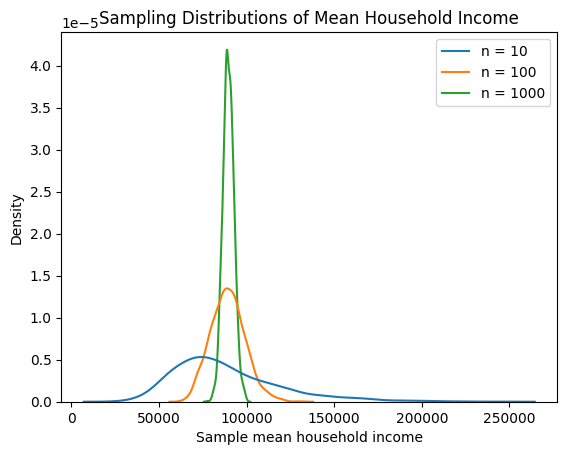

In [56]:
# your code here
means_10 = simulate_means(10, 2000)
means_100 = simulate_means(100, 2000)
means_1000 = simulate_means(1000, 2000)

means_table = pd.DataFrame({
    "n = 10": means_10,
    "n = 100": means_100,
    "n = 1000": means_1000
})

sb.kdeplot(data=means_table)
plt.xlabel("Sample mean household income")
plt.title("Sampling Distributions of Mean Household Income")
plt.show()

In [58]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert list(means_table.columns) == ["n = 10", "n = 100", "n = 1000"]
assert means_table.shape == (2000, 3)

### (b) Two facts

Two facts hold for an IID sample mean:
$\mathrm{E}[\bar X] = \mathrm{E}[X]$ and
$\mathrm{Var}[\bar X] = \mathrm{Var}[X] / n$. Check both against your
simulation by building a table **`sampling_table`** with one row per
sample size and three columns. The column `"mean of means"` holds the
mean of the simulated sample means, `"sd of means"` holds their standard
deviation, and `"sigma / sqrt(n)"` holds what the second fact says that
standard deviation should be, from `sigma` and `np.sqrt`.

Use `pd.DataFrame` with a dictionary of three lists and
`index=[10, 100, 1000]`, and display the table.

*Hint: the plenary 2.4 session’s “Two facts about the sample mean”
section builds a table of this shape.*

In [59]:
# your code here

sampling_table = pd.DataFrame({
    "mean of means": [
        means_10.mean(),
        means_100.mean(),
        means_1000.mean()
    ],
    "sd of means": [
        means_10.std(),
        means_100.std(),
        means_1000.std()
    ],
    "sigma / sqrt(n)": [
        sigma / np.sqrt(10),
        sigma / np.sqrt(100),
        sigma / np.sqrt(1000)
    ]
}, index=[10, 100, 1000])

sampling_table

,mean of means,sd of means,sigma / sqrt(n)
10,88402.544600,30639.753452,31652.686525
100,89374.044075,9796.414109,10009.458348
1000,89662.529825,3167.650067,3165.268652


In [60]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert list(sampling_table.index) == [10, 100, 1000]
assert list(sampling_table.columns) == ["mean of means", "sd of means", "sigma / sqrt(n)"]
assert (abs(sampling_table["mean of means"] / mu - 1) < 0.02).all()
assert (abs(sampling_table["sd of means"] / sampling_table["sigma / sqrt(n)"] - 1) < 0.1).all()
assert sampling_table.loc[10, "sd of means"] > sampling_table.loc[100, "sd of means"] > sampling_table.loc[1000, "sd of means"]

## Your survey: precision for your column

> **Motivation.** Your survey will estimate the mean of your column from
> 1,000 households as well. How far off will that estimate typically be?

Store the population standard deviation of `my_values` as
**`my_sigma`**. Simulate 2,000 sample means of size 100 from
`my_values`, as a Series called **`my_means_100`**. Then display, in one
dictionary, `my_sigma`, $\sigma / \sqrt{100}$, the standard deviation of
`my_means_100`, and $\sigma / \sqrt{1000}$.

`simulate_means` samples income only, so write the list comprehension on
`my_values` instead. Run the seed cell first.

*Hint: the plenary 2.3 session’s “Many samples” section builds a Series
of sample means from a comprehension, and Question 11 computed
$\sigma / \sqrt{n}$ with `np.sqrt`.*

In [61]:
np.random.seed(2026)

In [62]:
# your code here
my_sigma = my_values.std()

my_means_100 = pd.Series([
    my_values.sample(100).mean()
    for _ in range(2000)
])

{
    "my_sigma": my_sigma,
    "sigma / sqrt(100)": my_sigma / np.sqrt(100),
    "sd of my_means_100": my_means_100.std(),
    "sigma / sqrt(1000)": my_sigma / np.sqrt(1000)
}

{'my_sigma': 0.9325647522768497,
 'sigma / sqrt(100)': np.float64(0.09325647522768496),
 'sd of my_means_100': 0.0941025570620845,
 'sigma / sqrt(1000)': np.float64(0.029490286827855403)}

In [63]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert abs(my_sigma - my_values.std()) < 0.000001
assert type(my_means_100) == pd.Series and len(my_means_100) == 2000
assert abs(my_means_100.std() / (my_sigma / 10) - 1) < 0.1

# Part 5: Large samples (Plenary 2.5)

A real survey gets one sample. This part asks how far that one sample
mean can land from the truth, and ends with the size your survey needs.

## Question 12: Z-scores and the empirical rule

> **Motivation.** Incomes are badly skewed. Does the bell curve have
> anything to say about the average of a sample of them?

### (a) Two functions

Write two functions.

**`z_scores(values)`** takes a Series of numbers and returns a Series of
the same length, each value minus the mean of the Series, divided by its
standard deviation. Use the Series’ own mean and standard deviation, not
the population’s, so the result has mean 0 and standard deviation 1
exactly.

**`empirical_rule(values)`** takes a Series of numbers and returns a
**dictionary** with the integer keys `1`, `2` and `3`, holding the
proportion of Z-scores whose absolute value is **less than** 1, 2 and 3.
Use `z_scores` and the `abs` method.

Demonstrate both on `pd.Series([1, 2, 3])`, in one dictionary.

*Hint: the plenary 2.5 session’s “Two ways to standardize” section shows
which mean and standard deviation to use, and its `emp_rule` computes
the three proportions.*

In [64]:
# your code here
def z_scores(values):
    return (values - values.mean()) / values.std()

def empirical_rule(values):
    z = z_scores(values)
    return {
        1: (z.abs() < 1).mean(),
        2: (z.abs() < 2).mean(),
        3: (z.abs() < 3).mean()
    }

test_values = pd.Series([1, 2, 3])

{
    "z_scores": z_scores(test_values),
    "empirical_rule": empirical_rule(test_values)
}

{'z_scores': 0   -1.0
 1    0.0
 2    1.0
 dtype: float64,
 'empirical_rule': {1: np.float64(0.3333333333333333),
  2: np.float64(1.0),
  3: np.float64(1.0)}}

In [65]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert z_scores(pd.Series([1, 2, 3])).tolist() == [-1.0, 0.0, 1.0]
assert abs(z_scores(means_100).mean()) < 0.000001
assert abs(z_scores(means_100).std() - 1) < 0.000001
assert list(empirical_rule(pd.Series([1, 2, 3])).keys()) == [1, 2, 3]
assert abs(empirical_rule(pd.Series([1, 2, 3]))[1] - 1 / 3) < 0.000001
assert empirical_rule(pd.Series([1, 2, 3]))[2] == 1.0

### (b) The rule table

Apply `empirical_rule` to four things, the **population** itself, which
is `households["HINCP"]`, and the three simulated sampling
distributions. Put the four results in a `pd.DataFrame` called
**`rule_table`**, one column each, with the columns named
`"population"`, `"n = 10"`, `"n = 100"` and `"n = 1000"`, and display
it.

In [66]:
# your code here
rule_table = pd.DataFrame({
    "population": empirical_rule(households["HINCP"]),
    "n = 10": empirical_rule(means_10),
    "n = 100": empirical_rule(means_100),
    "n = 1000": empirical_rule(means_1000)
})

rule_table

,population,n = 10,n = 100,n = 1000
1,0.908764,0.7315,0.6835,0.6940
2,0.960947,0.9520,0.9570,0.9545
3,0.977109,0.9865,0.9955,0.9965


In [67]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert list(rule_table.columns) == ["population", "n = 10", "n = 100", "n = 1000"]
assert list(rule_table.index) == [1, 2, 3]
assert abs(rule_table.loc[1, "n = 1000"] - 0.68) < 0.05
assert abs(rule_table.loc[2, "n = 1000"] - 0.95) < 0.03
assert rule_table.loc[1, "population"] > 0.75

## Question 13: One sample

> **Motivation.** A real survey gets one sample and never sees the
> truth. What can it say about how far off it might be?

Everything so far looked at 2,000 samples at once. Your survey gets
**one**. Run the seed cell first.

In [68]:
np.random.seed(101)

### (a) Four numbers

Take one simple random sample of $n = 100$ incomes from
`households["HINCP"]` and call it **`one_sample`**. Store its mean as
**`xbar`** and the standard error of the mean for $n = 100$, computed
from `sigma`, as **`sem`**. Then display four numbers in one dictionary.
`"xbar"` is the mean of `one_sample`. `"error"` is `xbar` minus `mu`; in
real life you could not compute this, because you would not know `mu`,
but here you can. `"sem"` is the standard error of the mean for
$n = 100$, from `sigma`. `"z"` is the error divided by the SEM, the
number of standard errors this sample is off.

*Hint: the plenary 2.5 session’s “One sample and its standard error”
section computes the same four numbers for songs.*

In [70]:
# your code here
one_sample = households["HINCP"].sample(100)

xbar = one_sample.mean()
sem = sigma / np.sqrt(100)

{
    "xbar": xbar,
    "error": xbar - mu,
    "sem": sem,
    "z": (xbar - mu) / sem
}

{'xbar': np.float64(109202.1),
 'error': np.float64(19551.813320505622),
 'sem': np.float64(10009.45834816209),
 'z': np.float64(1.953333800933961)}

In [71]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert len(one_sample) == 100
assert abs(sem - sigma / 10) < 0.000001
assert abs((xbar - mu) / sem) < 4

### (b) The 2-SEM range

Use the Gaussian rule to give the range `mu - 2 * sem` to
`mu + 2 * sem`, inside which about 95% of sample means for $n = 100$
should fall. Store the ends as **`low`** and **`high`**. Then display
them, and the proportion of your simulated `means_100` that actually
fell in that range, in one dictionary. The `between(low, high)` method
gives `True` for each value inside the range, and the mean of that is
the proportion.

In [72]:
# your code here

low = mu - 2 * sem
high = mu + 2 * sem

{
    "low": low,
    "high": high,
    "proportion_in_range": means_100.between(low, high).mean()
}

{'low': np.float64(69631.36998317021),
 'high': np.float64(109669.20337581856),
 'proportion_in_range': np.float64(0.9605)}

In [73]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert low < mu < high
assert abs(means_100.between(low, high).mean() - 0.95) < 0.03

## Question 14: How big a sample?

> **Motivation.** The housing office has to decide how many households
> to pay for, and the answer depends on how precise it needs the result
> to be.

The housing office wants the survey’s mean income to land within **5,000
dollars** of the truth in about 95% of possible samples. By the Gaussian
rule, two standard errors must fit inside 5,000, so the SEM can be at
most 2,500. Solve $\sigma / \sqrt{n} = 2500$ for $n$ using your `sigma`,
and display, in one dictionary, the result as **`n_needed`**, the SEM
that $n = 1000$ gives, from `sigma`, and twice that SEM.

*Hint: the plenary 2.5 session’s “How big a sample?” section solves the
same equation.*

In [74]:
# your code here

n_needed = (sigma / 2500) ** 2

sem_1000 = sigma / np.sqrt(1000)

{
    "n_needed": n_needed,
    "sem_at_1000": sem_1000,
    "twice_sem_at_1000": 2 * sem_1000
}

{'n_needed': 1603.0281027774686,
 'sem_at_1000': np.float64(3165.268652477887),
 'twice_sem_at_1000': np.float64(6330.537304955774)}

In [75]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert 1590 < n_needed < 1620
assert abs(sigma / np.sqrt(n_needed) - 2500) < 0.01

## Your survey: one sample of your column

> **Motivation.** The single survey your city runs will produce one
> estimate for your column too. How many standard errors off did it
> land?

Take one simple random sample of 100 values from `my_values` and call it
**`my_sample`**. Store its mean as **`my_xbar`** and the standard error
of the mean for $n = 100$, from `my_sigma`, as **`my_sem`**. Display the
same four numbers as Question 13(a) in one dictionary, with the mean of
`my_values` in the role of `mu`. Run the seed cell first.

In [76]:
np.random.seed(101)

In [77]:
# your code here

my_sample = my_values.sample(100)

my_xbar = my_sample.mean()
my_sem = my_sigma / np.sqrt(100)

{
    "my_xbar": my_xbar,
    "error": my_xbar - my_values.mean(),
    "my_sem": my_sem,
    "z": (my_xbar - my_values.mean()) / my_sem
}

{'my_xbar': np.float64(0.66),
 'error': np.float64(0.20897836418757149),
 'my_sem': np.float64(0.09325647522768496),
 'z': np.float64(2.2408992370487137)}

In [78]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert len(my_sample) == 100
assert abs(my_sem - my_sigma / 10) < 0.000001
assert abs((my_xbar - my_values.mean()) / my_sem) < 4

In [79]:
!wget -q -N https://raw.githubusercontent.com/UM-Data-Science-101/data/main/Tools/print_notebook.py
from print_notebook import print_notebook, install_quarto
install_quarto()

'Quarto is installed. You can now print with print_notebook().'

In [81]:
print_notebook(two_columns=True, summary=False)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>